In [1]:
# mamba activate spatiocore_spatial_env
import tifffile
import os
from spatialdata.models import Image2DModel
import spatialdata_io
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import numpy as np
from spatialdata.models import ShapesModel
import anndata
import scanpy as sc
from spatialdata import SpatialData
from spatialdata import polygon_query
from spatialdata import bounding_box_query
# from napari_spatialdata import Interactive
from spatialdata.models import TableModel
from spatialdata_plot.pl.utils import set_zero_in_cmap_to_transparent
from spatialdata import SpatialData
from napari.utils.colormaps import Colormap
from napari_spatialdata import Interactive
import spatialdata as sd
from scipy import ndimage as ndi
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
import pickle

from spatialdata.transformations import (
    BaseTransformation,
    Identity,
    Sequence,
    align_elements_using_landmarks,
    get_transformation,
    set_transformation,
    Affine
)

In [2]:
# -----------------------------
# helper function
# -----------------------------
def add_cluster_from_pickle(andata, pkl_file, new_col, match_col="cell_id"):
    """
    Add clustering results from a pickle dictionary to andata.obs.

    The pickle file should contain:
        key   = original obs name
        value = cluster label
    """

    with open(pkl_file, "rb") as f:
        cluster_dict = pickle.load(f)

    # make sure dictionary keys are strings
    cluster_dict = {str(k): str(v) for k, v in cluster_dict.items()}

    # map cluster labels into AnnData
    andata.obs[new_col] = andata.obs[match_col].map(cluster_dict)

    # report mapping quality
    n_total = andata.n_obs
    n_missing = andata.obs[new_col].isna().sum()

    print(f"{new_col}")
    print(f"  total cells:   {n_total}")
    print(f"  matched cells: {n_total - n_missing}")
    print(f"  missing cells: {n_missing}")

    # convert to category for plotting
    andata.obs[new_col] = andata.obs[new_col].astype("category")

    return andata


In [3]:
pathout = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
pathdict = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res07'

andata = sc.read_h5ad(os.path.join(pathout, "adata_nb_processed.h5ad"))

In [4]:
pkl_dir = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res07'
andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_1.pkl"),
    "spatialleiden_weighted_1"
)

andata = add_cluster_from_pickle(       
    andata,
    os.path.join(pkl_dir, "stlieden_1_3.pkl"),
    "spatialleiden_weighted_1_3"    
)

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_1_5.pkl"),
    "spatialleiden_weighted_1_5"
)

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_1_8.pkl"),
    "spatialleiden_weighted_1_8"
)


spatialleiden_weighted_1
  total cells:   669261
  matched cells: 669261
  missing cells: 0
spatialleiden_weighted_1_3
  total cells:   669261
  matched cells: 669261
  missing cells: 0
spatialleiden_weighted_1_5
  total cells:   669261
  matched cells: 669261
  missing cells: 0
spatialleiden_weighted_1_8
  total cells:   669261
  matched cells: 669261
  missing cells: 0


In [5]:
import os
import pickle
pkl_dir = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc'
andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_1_5.pkl"),
    "spatialleiden_r1_weighted_1_5"
)

spatialleiden_r1_weighted_1_5
  total cells:   669261
  matched cells: 669261
  missing cells: 0


In [5]:
andata.obs["spatialleiden_weighted_1"] = andata.obs["spatialleiden_weighted_1"].astype(str)
andata.obs["spatialleiden_weighted_1_8"] = andata.obs["spatialleiden_weighted_1_8"].astype(str)

map_spatialleiden_r1 = dict(zip(andata.obs['cell_id'], andata.obs["spatialleiden_weighted_1"]))
map_spatialleiden_r1_8 = dict(zip(andata.obs['cell_id'], andata.obs["spatialleiden_weighted_1_8"]))

In [6]:
path_zarr = '/data/HiTIF/data/spatialomics/neuroblastoma/data/SCAF4480/PrimaryAnalysisOutput/SCAF4480_PA_xenium/nb_orig_label_v1.zarr'
sdata = sd.read_zarr(path_zarr)

/tmp/ipykernel_924226/1456852835.py:2: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata = sd.read_zarr(path_zarr)
no parent found for <ome_zarr.reader.Label object at 0x155485f82350>: None
no parent found for <ome_zarr.reader.Label object at 0x155485811c10>: None


In [7]:
class PunchPlotter:
    def __init__(self, sdata,element_name):
        self.sdata = sdata
        self.element_name = element_name
        self.sdata_crop = self.crop_sdata()
        
    def crop_sdata(self):
        extent = sd.get_extent(
            self.sdata[self.element_name],
            coordinate_system="global",
            exact=True,
        )

        xmin, xmax = extent["x"]
        ymin, ymax = extent["y"]

        sdata_cropped = self.sdata.query.bounding_box(
            min_coordinate=[xmin, ymin],
            max_coordinate=[xmax, ymax],
            axes=("x", "y"),
            target_coordinate_system="global",
        )
        return sdata_cropped

    def plot_punch(self, colname,colname_map,dpi = 100):
        self.sdata_crop['table'].obs[colname] = self.sdata_crop['table'].obs['cell_id'].map(colname_map)
        self.sdata_crop['table'].obs[colname] = self.sdata_crop['table'].obs[colname].astype('category')
        return self.sdata_crop.pl.render_labels('cell_labels', color=colname).pl.show(coordinate_systems='global', figsize=(10,10), dpi=dpi, na_in_legend=False)

In [8]:
sdata_obj = PunchPlotter(sdata = sdata,element_name = '21')

/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


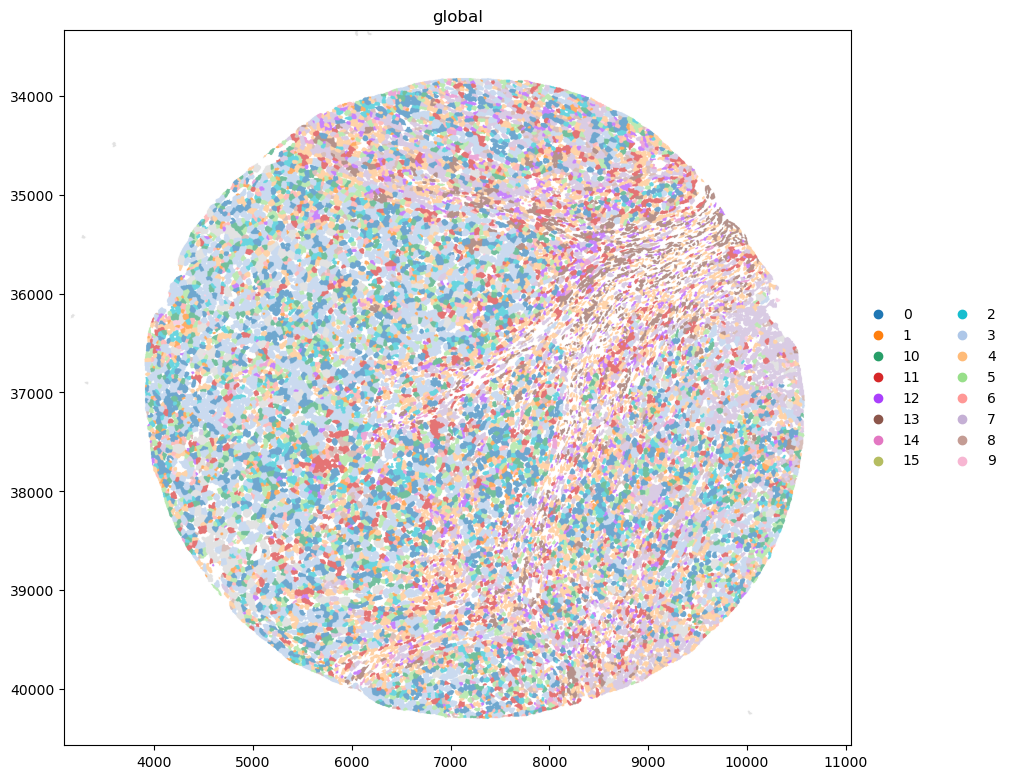

In [9]:
sdata_obj.plot_punch(colname= 'spatialleiden_weighted_1',colname_map = map_spatialleiden_r1)

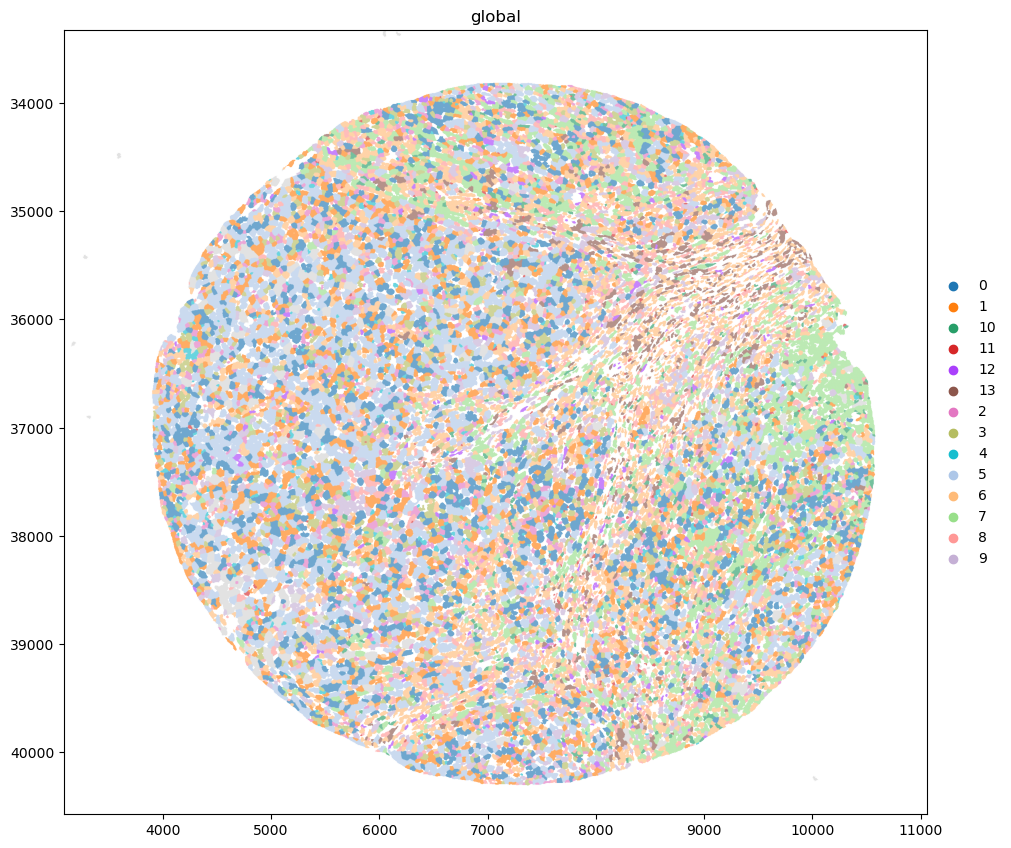

In [10]:
sdata_obj.plot_punch(colname= 'spatialleiden_weighted_1_8',colname_map = map_spatialleiden_r1_8)

In [17]:
np.linspace(5,25,5,dtype = np.float64)

array([ 5., 10., 15., 20., 25.])